<div style="text-align:center">

# Hands-On Lab-II — Student Final Grade Prediction Using Machine Learning

</div>

**Datasets:** `student-mat.csv` (Mathematics, 395 records) and `student-por.csv` (Portuguese, 649 records)  
**Target variable:** `G3` (final grade)  **Algorithm:** Linear Regression  **Metrics:** MAE, MSE, RMSE, R²

> As per the General Instructions, the Mathematics and Portuguese datasets are treated as **two separate datasets** and every step is carried out independently for each of them.

---
# Task 1: Problem Definition and Data Understanding (2 Marks)

### 1.1 Objective
Academic performance depends on many factors: personal background, family conditions, study habits, school support, social environment and earlier grades. The objective is to build a Machine Learning model that uses this information to **predict a student's final grade (G3)** and to measure how accurately it can do so. Such a model can help teachers identify students who may need additional academic support *before* the final result is known.

### 1.2 Type of ML problem
| Question | Answer |
|---|---|
| Learning paradigm | **Supervised learning** – every record has a known label (the real G3) to learn from |
| Task type | **Regression** – G3 is a numerical score (0–20), not a class label |
| Algorithm used | **Linear Regression** (as required by the lab) |

### 1.3 Target variable and its significance
`G3` is the **final-period grade** on a 0–20 scale. It is the end result of the school year and the quantity teachers and institutions care about most, so it is the variable we predict. It must **never** be included among the input features (that would be data leakage).

### 1.4 Input features that may influence the final grade
| Group | Attributes |
|---|---|
| Demographic | `school, sex, age, address, famsize, Pstatus` |
| Family background | `Medu, Fedu, Mjob, Fjob, guardian, famrel, famsup` |
| Study habits / school | `studytime, traveltime, failures, schoolsup, paid, activities, nursery, higher, reason, absences` |
| Social / lifestyle | `freetime, goout, Dalc, Walc, romantic, internet, health` |
| Earlier academic performance | `G1` (1st period grade), `G2` (2nd period grade) |

**Note on G1 and G2.** They are by far the strongest predictors, because a student's earlier grades are very close to the final grade. The instructions say their use *depends on the intended prediction scenario*, so this notebook evaluates two scenarios:
* **Scenario A – "mid-year" prediction:** all features incl. G1 and G2 (main model, Tasks 3–5).
* **Scenario B – "early" prediction:** G1 and G2 removed, using only background/behaviour features (compared in Task 5).

### 1.5 Overall Machine Learning workflow
1. **Problem definition** – supervised regression, target G3.  
2. **Data loading & exploration** – shape, types, statistics, missing values, duplicates, target distribution.  
3. **Preprocessing** – separate X / y, drop G3 from X, impute, encode categoricals, scale numericals.  
4. **Train–test split** – done **before** fitting any preprocessing step, to avoid data leakage.  
5. **Model development** – train Linear Regression on the training set.  
6. **Prediction** – predict G3 for the unseen test set and compare with actual grades.  
7. **Evaluation & interpretation** – MAE, MSE, RMSE, R², plots, limitations and improvements.

---
# Task 2: Dataset Exploration (2 Marks)
### 2.1 Import the required libraries

In [8]:
import warnings
warnings.filterwarnings("ignore")

import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42
print("Libraries imported successfully")
print("pandas", pd.__version__, "| numpy", np.__version__)

Libraries imported successfully
pandas 2.2.3 | numpy 2.4.6


### 2.2 Load both datasets into separate DataFrames

In [9]:
def find_csv(pattern):
    # looks for the file in the current folder (and the upload folder if running there)
    for folder in [".", "/content/sample_data"]:
        hits = sorted(glob.glob(os.path.join(folder, pattern)))
        if hits:
            return hits[0]
    raise FileNotFoundError(pattern)

mat_path = find_csv("student-mat*.csv")
por_path = find_csv("student-por (1)*.csv")

df_mat = pd.read_csv(mat_path)      # Mathematics
df_por = pd.read_csv(por_path)      # Portuguese
print("Datasets loaded successfully")
print("Mathematics :", os.path.basename(mat_path))
print("Portuguese  :", os.path.basename(por_path))

Datasets loaded successfully
Mathematics : student-mat.csv
Portuguese  : student-por (1).csv


### 2.3 First five and last five records of each dataset

In [10]:
print("MATHEMATICS - first five records")
display(df_mat.head())
print("MATHEMATICS - last five records")
display(df_mat.tail())

MATHEMATICS - first five records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


MATHEMATICS - last five records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,course,other,1,2,2,no,yes,yes,no,yes,yes,no,no,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,course,other,1,1,3,no,no,no,no,no,yes,no,no,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,course,father,1,1,0,no,no,no,no,yes,yes,yes,no,3,2,3,3,3,5,5,8,9,9


In [11]:
print("PORTUGUESE - first five records")
display(df_por.head())
print("PORTUGUESE - last five records")
display(df_por.tail())

PORTUGUESE - first five records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


PORTUGUESE - last five records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
644,MS,F,19,R,GT3,T,2,3,services,other,course,mother,1,3,1,no,no,no,yes,no,yes,yes,no,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,course,mother,1,2,0,no,yes,no,no,yes,yes,yes,no,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,course,mother,2,2,0,no,no,no,yes,yes,yes,no,no,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,6,10,10,10
648,MS,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,4,10,11,11


### 2.4 Number of rows and columns

In [12]:
shape_tbl = pd.DataFrame({"Rows": [df_mat.shape[0], df_por.shape[0]],
                          "Columns": [df_mat.shape[1], df_por.shape[1]]},
                         index=["Mathematics", "Portuguese"])
display(shape_tbl)

,Rows,Columns
Mathematics,395,33
Portuguese,649,33


### 2.5 Column names and data types

In [13]:
print("Column names:", list(df_mat.columns), "\n")
print("Same columns in both datasets:", list(df_mat.columns) == list(df_por.columns), "\n")
print("=== MATHEMATICS info ===")
df_mat.info()
print("\n=== PORTUGUESE info ===")
df_por.info()

Column names: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3'] 

Same columns in both datasets: True 

=== MATHEMATICS info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  rea

### 2.6 Descriptive statistics

In [14]:
print("MATHEMATICS - numerical summary")
display(df_mat.describe().T.round(2))
print("MATHEMATICS - categorical summary")
display(df_mat.describe(include="object").T)

MATHEMATICS - numerical summary


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


MATHEMATICS - categorical summary


,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344


In [15]:
print("PORTUGUESE - numerical summary")
display(df_por.describe().T.round(2))
print("PORTUGUESE - categorical summary")
display(df_por.describe(include="object").T)

PORTUGUESE - numerical summary


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


PORTUGUESE - categorical summary


,count,unique,top,freq
school,649,2,GP,423
sex,649,2,F,383
address,649,2,U,452
famsize,649,2,GT3,457
Pstatus,649,2,T,569
Mjob,649,5,other,258
Fjob,649,5,other,367
reason,649,4,course,285
guardian,649,3,mother,455
schoolsup,649,2,no,581


### 2.7 Missing values and duplicate records

In [16]:
check = pd.DataFrame({
    "Missing values (Math)": [df_mat.isna().sum().sum()],
    "Duplicate rows (Math)": [df_mat.duplicated().sum()],
    "Missing values (Por)":  [df_por.isna().sum().sum()],
    "Duplicate rows (Por)":  [df_por.duplicated().sum()],
}, index=["count"]).T
display(check)
print("Columns with missing values (Math):", df_mat.columns[df_mat.isna().any()].tolist())
print("Columns with missing values (Por) :", df_por.columns[df_por.isna().any()].tolist())

,count
Missing values (Math),0
Duplicate rows (Math),0
Missing values (Por),0
Duplicate rows (Por),0


Columns with missing values (Math): []
Columns with missing values (Por) : []


### 2.8 Distribution of the target variable (G3)

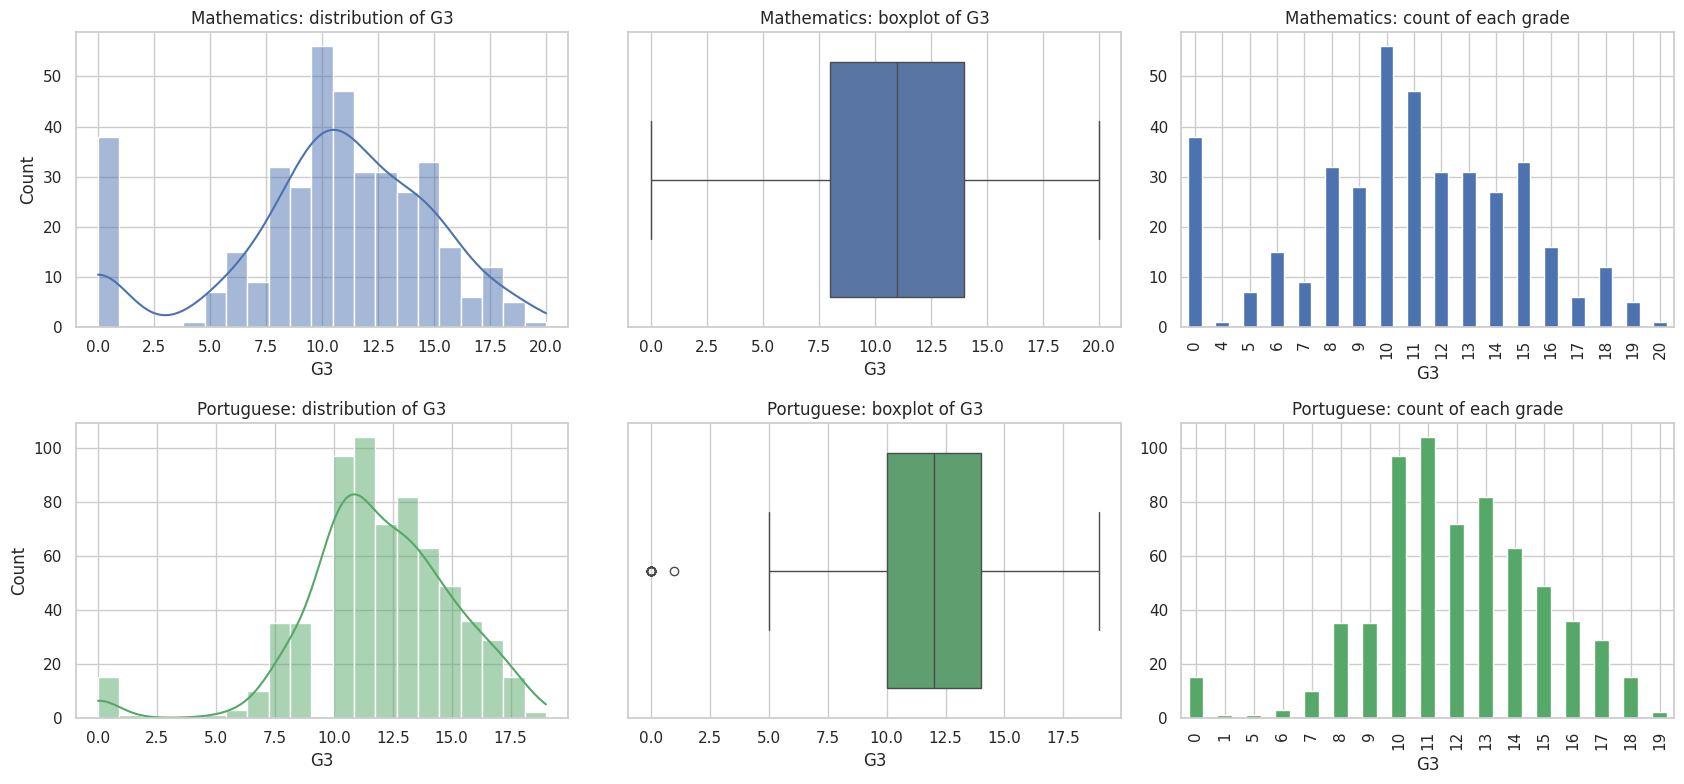

,count,mean,std,min,25%,50%,75%,max,skewness,students with G3 = 0
Mathematics,395.0,10.42,4.58,0.0,8.0,11.0,14.0,20.0,-0.73,38
Portuguese,649.0,11.91,3.23,0.0,10.0,12.0,14.0,19.0,-0.91,15


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for row, (name, d, col) in enumerate([("Mathematics", df_mat, "#4c72b0"), ("Portuguese", df_por, "#55a868")]):
    sns.histplot(d["G3"], bins=21, kde=True, color=col, ax=axes[row, 0])
    axes[row, 0].set_title(f"{name}: distribution of G3")
    sns.boxplot(x=d["G3"], color=col, ax=axes[row, 1])
    axes[row, 1].set_title(f"{name}: boxplot of G3")
    d["G3"].value_counts().sort_index().plot(kind="bar", color=col, ax=axes[row, 2])
    axes[row, 2].set_title(f"{name}: count of each grade"); axes[row, 2].set_xlabel("G3")
plt.tight_layout(); plt.show()

g3 = pd.DataFrame({n: d["G3"].describe() for n, d in [("Mathematics", df_mat), ("Portuguese", df_por)]}).T
g3["skewness"] = [df_mat["G3"].skew(), df_por["G3"].skew()]
g3["students with G3 = 0"] = [(df_mat["G3"] == 0).sum(), (df_por["G3"] == 0).sum()]
display(g3.round(2))

### 2.9 Numerical and categorical attributes

In [18]:
target = "G3"
num_cols = df_mat.drop(columns=target).select_dtypes(include="number").columns.tolist()
cat_cols = df_mat.drop(columns=target).select_dtypes(exclude="number").columns.tolist()
print(f"NUMERICAL attributes ({len(num_cols)}):\n{num_cols}\n")
print(f"CATEGORICAL attributes ({len(cat_cols)}):\n{cat_cols}\n")
print("Same split in Portuguese data:",
      num_cols == df_por.drop(columns=target).select_dtypes(include="number").columns.tolist()
      and cat_cols == df_por.drop(columns=target).select_dtypes(exclude="number").columns.tolist())

NUMERICAL attributes (15):
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

CATEGORICAL attributes (17):
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Same split in Portuguese data: True


### 2.10 Exploratory analysis: relationship of features with G3

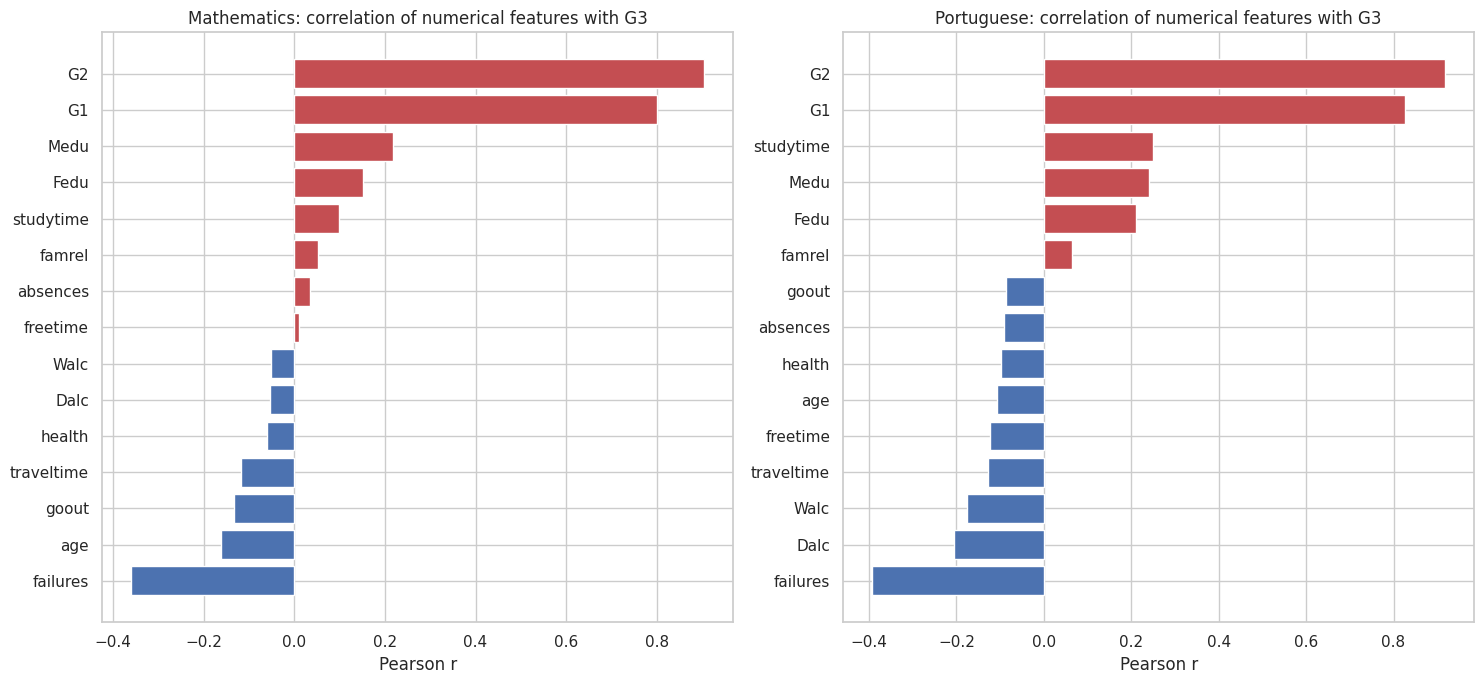

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for a, (name, d) in zip(axes, [("Mathematics", df_mat), ("Portuguese", df_por)]):
    c = d[num_cols + [target]].corr()[target].drop(target).sort_values()
    a.barh(c.index, c.values, color=np.where(c.values > 0, "#c44e52", "#4c72b0"))
    a.set_title(f"{name}: correlation of numerical features with G3"); a.set_xlabel("Pearson r")
plt.tight_layout(); plt.show()

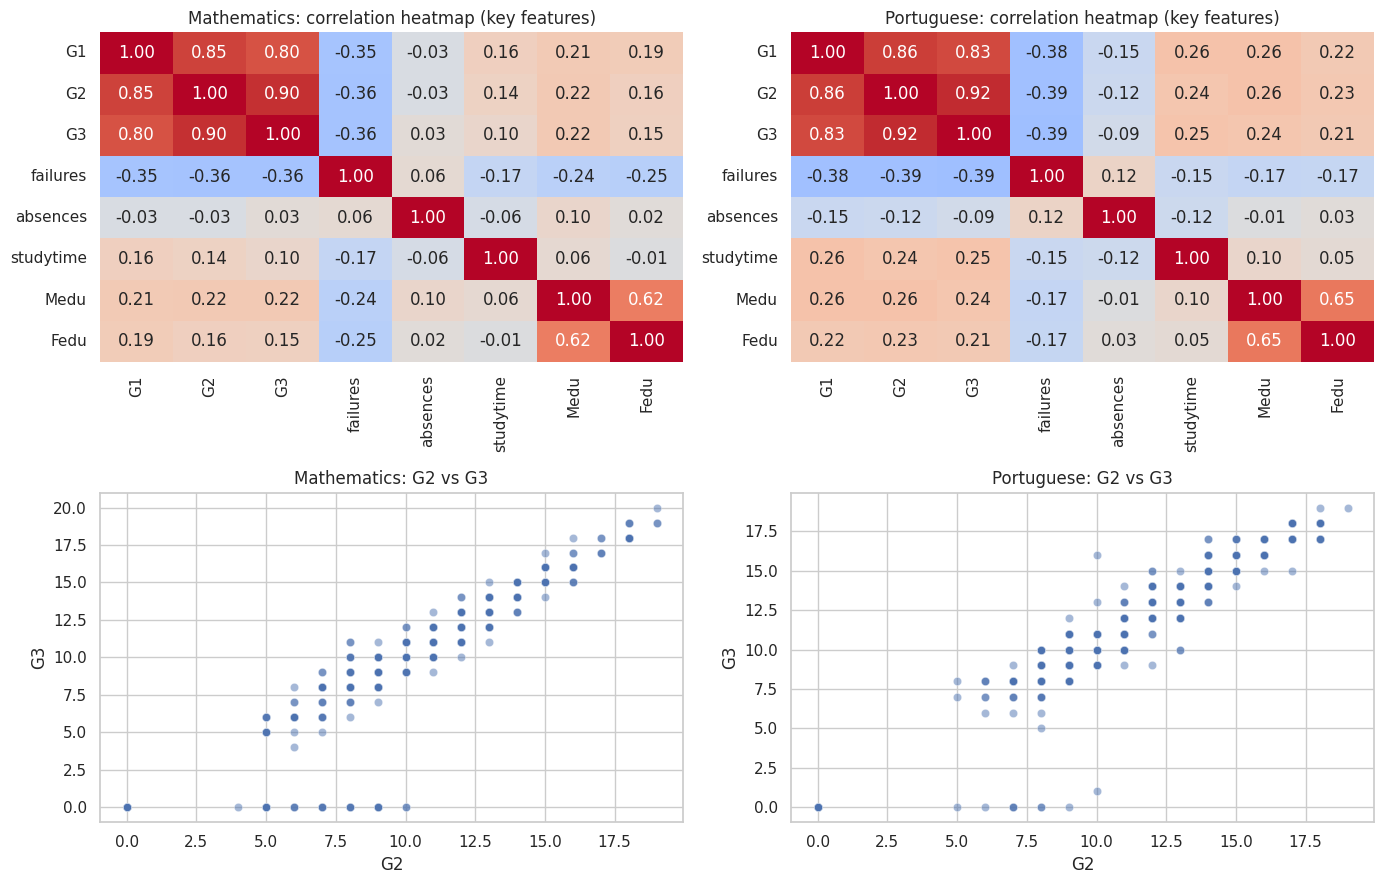

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for j, (name, d) in enumerate([("Mathematics", df_mat), ("Portuguese", df_por)]):
    sns.heatmap(d[["G1", "G2", "G3", "failures", "absences", "studytime", "Medu", "Fedu"]].corr(),
                annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0, j], cbar=False)
    axes[0, j].set_title(f"{name}: correlation heatmap (key features)")
    sns.scatterplot(data=d, x="G2", y="G3", alpha=.5, ax=axes[1, j])
    axes[1, j].set_title(f"{name}: G2 vs G3")
plt.tight_layout(); plt.show()

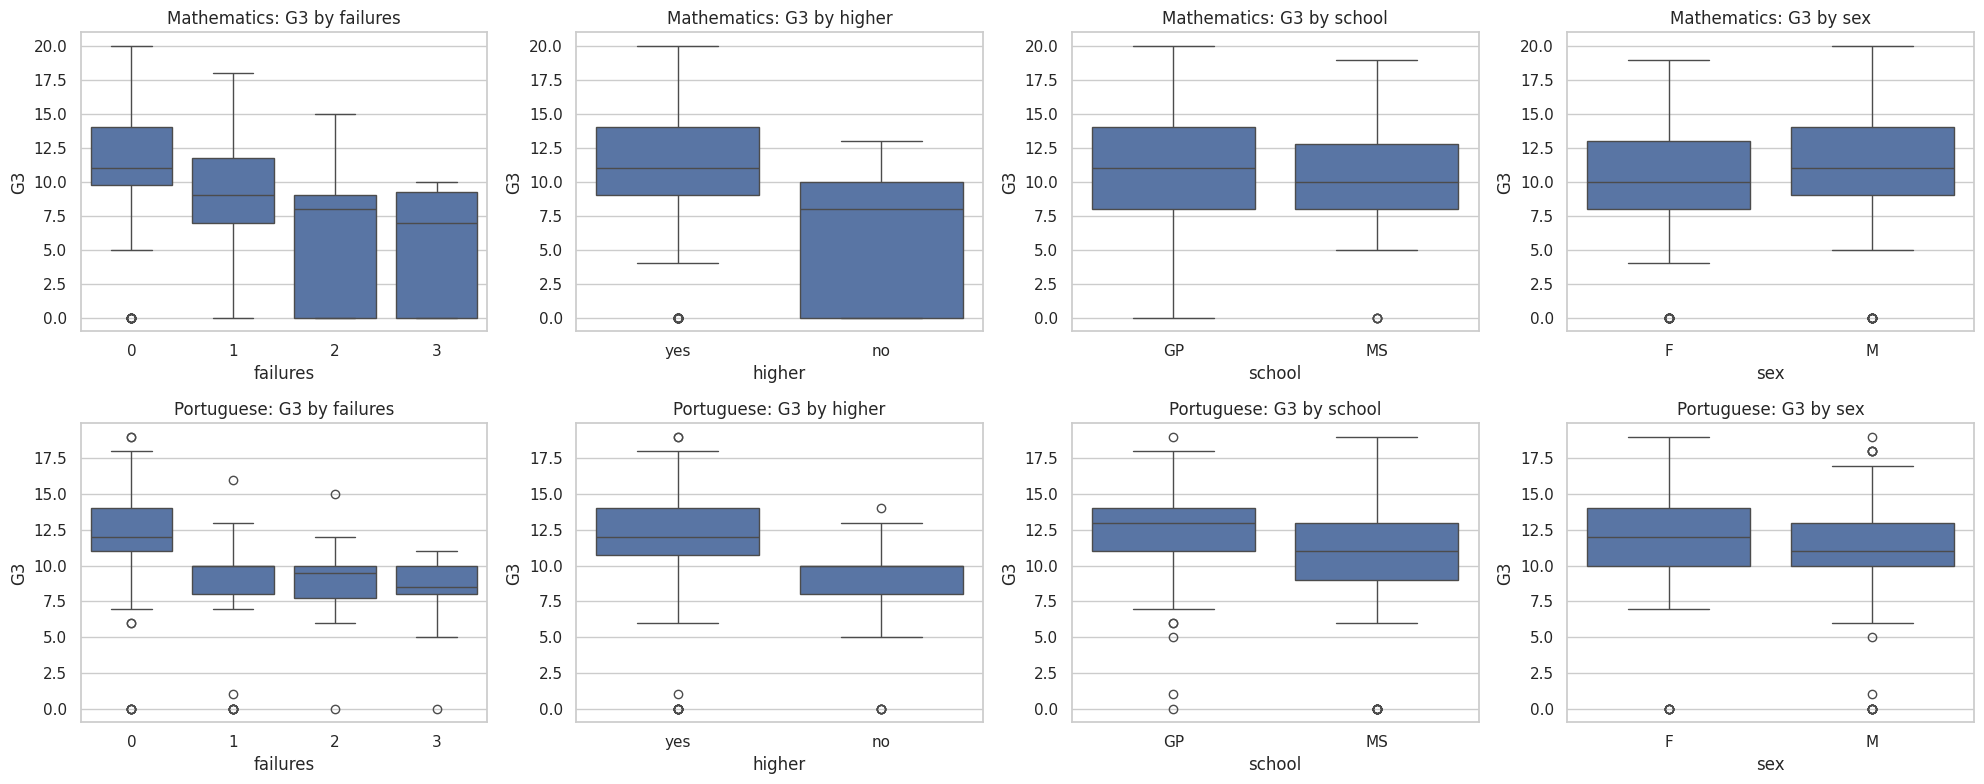

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, (name, d) in enumerate([("Mathematics", df_mat), ("Portuguese", df_por)]):
    for j, c in enumerate(["failures", "higher", "school", "sex"]):
        sns.boxplot(data=d, x=c, y="G3", ax=axes[i, j]); axes[i, j].set_title(f"{name}: G3 by {c}")
plt.tight_layout(); plt.show()


### Observations (Task 2)
* **Size:** Mathematics has 395 records and Portuguese 649, both with 33 columns (30 background attributes + G1, G2 + the target G3). Both share identical columns; of the 32 input attributes, 15 are numerical (incl. G1, G2) and 17 categorical.
* **Data quality:** there are **no missing values and no duplicate rows** in either dataset, so no rows had to be removed or imputed.
* **Target G3:** Mathematics averages 10.42 (std 4.58), Portuguese 11.91 (std 3.23). Both are **left-skewed** (−0.73 and −0.91) because of a small group of students with G3 = 0 (38 in Mathematics, 15 in Portuguese), most likely students who dropped out or did not sit the final exam. These zeros are the hardest records for a linear model to predict.
* **Relationships:** `G2` (r = 0.90 Math, 0.92 Portuguese) and `G1` (r = 0.80 / 0.83) are overwhelmingly the strongest correlates of G3. `failures` is the strongest negative factor (r = −0.36 / −0.39), while parental education (`Medu`) and `studytime` have a modest positive effect. Students who want to pursue higher education (`higher = yes`) score clearly higher.


---
# Task 3: Data Preprocessing (3 Marks)
The two datasets are preprocessed **independently**. The order of operations matters for avoiding **data leakage**: the data is split *first*, and the imputers, encoder and scaler are then fitted on the **training set only** and merely applied (`transform`) to the test set.

### 3.1 – 3.2 Separate input features (X) and target (y); remove G3 from X

In [22]:
def split_xy(df):
    X = df.drop(columns=["G3"])      # G3 removed from the inputs
    y = df["G3"]
    return X, y

X_mat, y_mat = split_xy(df_mat)
X_por, y_por = split_xy(df_por)

print("Mathematics : X", X_mat.shape, "| y", y_mat.shape, "| G3 in X?", "G3" in X_mat.columns)
print("Portuguese  : X", X_por.shape, "| y", y_por.shape, "| G3 in X?", "G3" in X_por.columns)

Mathematics : X (395, 32) | y (395,) | G3 in X? False
Portuguese  : X (649, 32) | y (649,) | G3 in X? False


### 3.3 Identify numerical and categorical columns

In [23]:
def column_types(X):
    return (X.select_dtypes(include="number").columns.tolist(),
            X.select_dtypes(exclude="number").columns.tolist())

num_mat, cat_mat = column_types(X_mat)
num_por, cat_por = column_types(X_por)
print(f"Mathematics: {len(num_mat)} numerical, {len(cat_mat)} categorical")
print("  categorical:", cat_mat)
print(f"Portuguese : {len(num_por)} numerical, {len(cat_por)} categorical")
print("  Unique values per categorical column (Math):")
print({c: X_mat[c].nunique() for c in cat_mat})

Mathematics: 15 numerical, 17 categorical
  categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Portuguese : 15 numerical, 17 categorical
  Unique values per categorical column (Math):
{'school': 2, 'sex': 2, 'address': 2, 'famsize': 2, 'Pstatus': 2, 'Mjob': 5, 'Fjob': 5, 'reason': 4, 'guardian': 3, 'schoolsup': 2, 'famsup': 2, 'paid': 2, 'activities': 2, 'nursery': 2, 'higher': 2, 'internet': 2, 'romantic': 2}


### 3.4 Encoding of categorical variables, 3.5 Missing values
* **Categorical → numerical:** *One-Hot Encoding* (`drop="first"` to avoid the dummy-variable trap, which matters for Linear Regression). The categorical columns have no meaningful order (e.g. `Mjob`, `reason`), and the binary ones (`yes/no`, `F/M`) become a single 0/1 column.
* **Missing values:** none are present (checked in Task 2), but the pipeline still contains imputers (median for numbers, most-frequent for categories) so that it is safe on new data.
* **Scaling:** numerical features are standardised (mean 0, std 1) so that coefficients are comparable.

In [24]:
def build_preprocessor(num_features, cat_features):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numeric, num_features),
                              ("cat", categorical, cat_features)], verbose_feature_names_out=False)

print("Missing values - Math:", int(X_mat.isna().sum().sum()), "| Portuguese:", int(X_por.isna().sum().sum()))

Missing values - Math: 0 | Portuguese: 0


### 3.6 Train–test split (80 % train / 20 % test)

In [25]:
Xtr_mat, Xte_mat, ytr_mat, yte_mat = train_test_split(X_mat, y_mat, test_size=0.20, random_state=RANDOM_STATE)
Xtr_por, Xte_por, ytr_por, yte_por = train_test_split(X_por, y_por, test_size=0.20, random_state=RANDOM_STATE)

print("Mathematics : train", Xtr_mat.shape, "| test", Xte_mat.shape)
print("Portuguese  : train", Xtr_por.shape, "| test", Xte_por.shape)
print("Row overlap between train and test (Math, Por):",
      len(set(Xtr_mat.index) & set(Xte_mat.index)), len(set(Xtr_por.index) & set(Xte_por.index)))
print("Mean G3 train/test - Math:", round(ytr_mat.mean(), 2), "/", round(yte_mat.mean(), 2),
      "| Por:", round(ytr_por.mean(), 2), "/", round(yte_por.mean(), 2))

Mathematics : train (316, 32) | test (79, 32)
Portuguese  : train (519, 32) | test (130, 32)
Row overlap between train and test (Math, Por): 0 0
Mean G3 train/test - Math: 10.33 / 10.77 | Por: 11.79 / 12.35


### 3.7 Apply preprocessing without data leakage (fit on train only)

In [26]:
prep_mat = build_preprocessor(num_mat, cat_mat)
prep_por = build_preprocessor(num_por, cat_por)

Xtr_mat_p = pd.DataFrame(prep_mat.fit_transform(Xtr_mat), columns=prep_mat.get_feature_names_out(), index=Xtr_mat.index)
Xte_mat_p = pd.DataFrame(prep_mat.transform(Xte_mat),     columns=prep_mat.get_feature_names_out(), index=Xte_mat.index)
Xtr_por_p = pd.DataFrame(prep_por.fit_transform(Xtr_por), columns=prep_por.get_feature_names_out(), index=Xtr_por.index)
Xte_por_p = pd.DataFrame(prep_por.transform(Xte_por),     columns=prep_por.get_feature_names_out(), index=Xte_por.index)

print("Mathematics : processed train", Xtr_mat_p.shape, "| test", Xte_mat_p.shape)
print("Portuguese  : processed train", Xtr_por_p.shape, "| test", Xte_por_p.shape)
print("Missing values after processing:", int(Xtr_mat_p.isna().sum().sum() + Xte_mat_p.isna().sum().sum()
                                             + Xtr_por_p.isna().sum().sum() + Xte_por_p.isna().sum().sum()))
print("All columns numeric:", all(Xtr_mat_p.dtypes != object) and all(Xtr_por_p.dtypes != object))
display(Xtr_mat_p.head())

Mathematics : processed train (316, 41) | test (79, 41)
Portuguese  : processed train (519, 41) | test (130, 41)
Missing values after processing: 0
All columns numeric: True


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,school_MS,sex_M,address_U,famsize_LE3,Pstatus_T,...,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
181,-0.586396,0.246437,0.423207,-0.625779,-0.056853,-0.456744,0.064432,-1.195981,-0.144396,-0.55443,-0.266496,-0.368473,-0.464408,0.332050,0.626163,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0
194,-0.586396,-0.680636,0.423207,0.828236,-1.254553,-0.456744,1.195575,-0.214345,-0.144396,-0.55443,-1.039089,-0.368473,-0.702257,0.643409,0.892831,0.0,1.0,1.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
173,-0.586396,-1.607709,0.423207,-0.625779,-0.056853,3.628097,0.064432,-0.214345,1.644982,-0.55443,-1.039089,-0.368473,-0.702257,-0.913385,-0.973844,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0
63,-0.586396,1.173510,0.423207,-0.625779,1.140847,-0.456744,-1.066710,0.767292,0.750293,0.55443,1.278690,0.341512,-0.464408,-0.290667,-0.440508,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
253,-0.586396,-0.680636,-1.434203,0.828236,-1.254553,-0.456744,-1.066710,-0.214345,-1.039085,-0.55443,0.506097,-0.368473,-0.702257,-0.913385,-0.440508,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [27]:
# Proof of no leakage: the scaler learned its statistics from the TRAIN set only,
# so train columns have mean 0 / std 1 while test columns are close to, but not exactly, 0 / 1.
chk = pd.DataFrame({"train mean": Xtr_mat_p[["age", "G1", "G2", "absences"]].mean(),
                    "train std":  Xtr_mat_p[["age", "G1", "G2", "absences"]].std(),
                    "test mean":  Xte_mat_p[["age", "G1", "G2", "absences"]].mean(),
                    "test std":   Xte_mat_p[["age", "G1", "G2", "absences"]].std()}).round(3)
display(chk)

,train mean,train std,test mean,test std
age,-0.0,1.002,-0.187,1.017
G1,0.0,1.002,-0.038,1.159
G2,-0.0,1.002,0.083,1.013
absences,-0.0,1.002,-0.117,0.717



### Observations (Task 3)
* G3 was removed from X; X has 32 columns in each dataset (15 numerical incl. G1 and G2, 17 categorical; see the column-type output above) and expands to **41 numerical columns** after one-hot encoding.
* The split gives **316 / 79** (Math) and **519 / 130** (Portuguese) train/test rows with no overlap.
* The small difference between train and test means/stds in the leakage check (e.g. test mean of `age` = −0.19 rather than 0) confirms that the scaler was **fitted on the training data only**.


---
# Task 4: Model Development and Prediction (2 Marks)
### 4.1 – 4.3 Import libraries, create and train the Linear Regression model
(Libraries were imported in Task 2. Scenario A: all features, including G1 and G2.)

In [28]:
lr_mat = LinearRegression()
lr_por = LinearRegression()

lr_mat.fit(Xtr_mat_p, ytr_mat)      # trained on the training data only
lr_por.fit(Xtr_por_p, ytr_por)

print("Models trained successfully")
print("Mathematics : intercept = %.3f, number of coefficients = %d" % (lr_mat.intercept_, len(lr_mat.coef_)))
print("Portuguese  : intercept = %.3f, number of coefficients = %d" % (lr_por.intercept_, len(lr_por.coef_)))
print("R² on TRAINING data -> Math: %.4f | Portuguese: %.4f" %
      (lr_mat.score(Xtr_mat_p, ytr_mat), lr_por.score(Xtr_por_p, ytr_por)))

Models trained successfully
Mathematics : intercept = 10.512, number of coefficients = 41
Portuguese  : intercept = 12.142, number of coefficients = 41
R² on TRAINING data -> Math: 0.8656 | Portuguese: 0.8583


**What the model learned** – the largest (standardised) coefficients show which features influence the predicted final grade most:

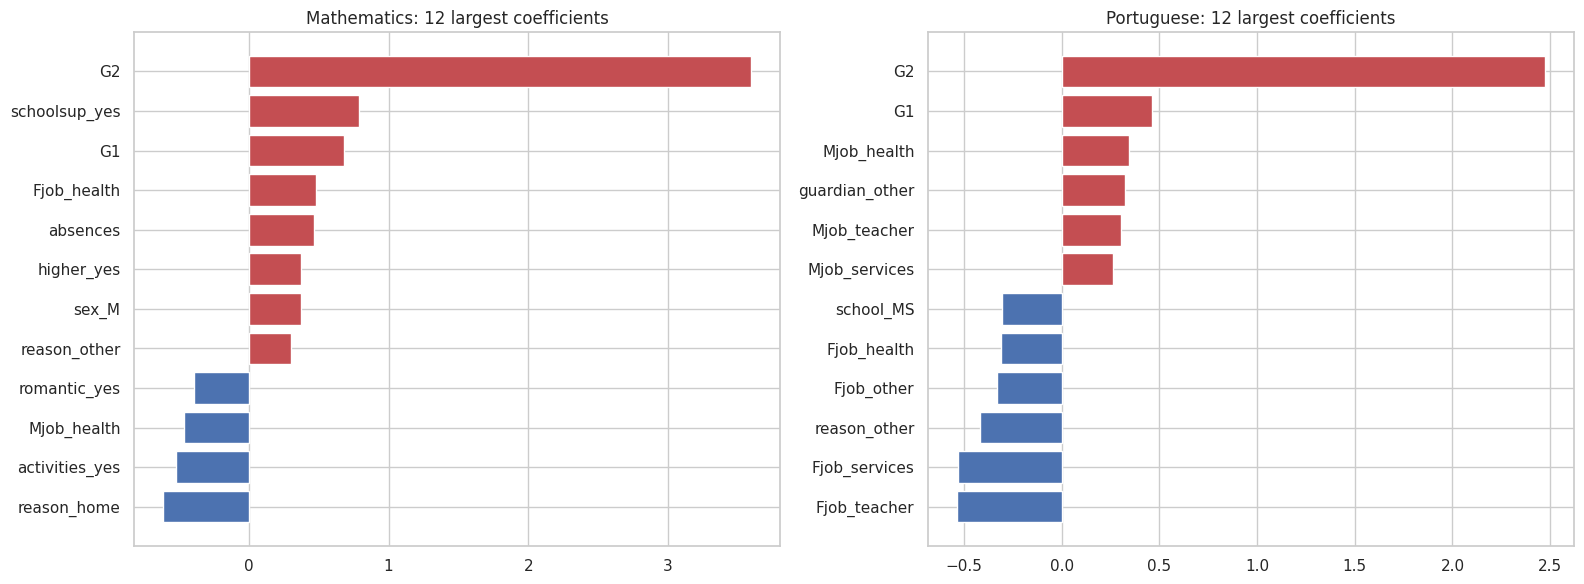

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for a, (name, m, cols) in zip(axes, [("Mathematics", lr_mat, Xtr_mat_p.columns), ("Portuguese", lr_por, Xtr_por_p.columns)]):
    coef = pd.Series(m.coef_, index=cols)
    top = coef.reindex(coef.abs().sort_values(ascending=False).index[:12]).sort_values()
    a.barh(top.index, top.values, color=np.where(top.values > 0, "#c44e52", "#4c72b0"))
    a.set_title(f"{name}: 12 largest coefficients")
plt.tight_layout(); plt.show()

### 4.4 Predict final grades for the test set

In [30]:
pred_mat = lr_mat.predict(Xte_mat_p)
pred_por = lr_por.predict(Xte_por_p)
print("Predictions generated -> Math:", pred_mat.shape, "| Portuguese:", pred_por.shape)

Predictions generated -> Math: (79,) | Portuguese: (130,)


### 4.5 – 4.6 Display and compare actual vs predicted grades

In [31]:
cmp_mat = pd.DataFrame({"Actual G3": yte_mat.values, "Predicted G3": pred_mat.round(2)}, index=yte_mat.index)
cmp_mat["Error (Actual - Predicted)"] = (cmp_mat["Actual G3"] - cmp_mat["Predicted G3"]).round(2)
cmp_mat["Absolute error"] = cmp_mat["Error (Actual - Predicted)"].abs()
print("MATHEMATICS - actual vs predicted (first 15 test students)")
display(cmp_mat.head(15))

MATHEMATICS - actual vs predicted (first 15 test students)


,Actual G3,Predicted G3,Error (Actual - Predicted),Absolute error
78,10,6.00,4.00,4.00
371,12,11.53,0.47,0.47
248,5,2.87,2.13,2.13
55,10,8.80,1.20,1.20
390,9,8.55,0.45,0.45
223,13,11.89,1.11,1.11
42,18,19.10,-1.10,1.10
234,6,7.17,-1.17,1.17
316,0,7.41,-7.41,7.41
116,14,12.31,1.69,1.69


In [32]:
cmp_por = pd.DataFrame({"Actual G3": yte_por.values, "Predicted G3": pred_por.round(2)}, index=yte_por.index)
cmp_por["Error (Actual - Predicted)"] = (cmp_por["Actual G3"] - cmp_por["Predicted G3"]).round(2)
cmp_por["Absolute error"] = cmp_por["Error (Actual - Predicted)"].abs()
print("PORTUGUESE - actual vs predicted (first 15 test students)")
display(cmp_por.head(15))

PORTUGUESE - actual vs predicted (first 15 test students)


,Actual G3,Predicted G3,Error (Actual - Predicted),Absolute error
636,19,18.40,0.60,0.60
220,12,11.83,0.17,0.17
594,18,18.56,-0.56,0.56
429,11,10.81,0.19,0.19
72,11,11.74,-0.74,0.74
448,17,16.52,0.48,0.48
181,18,17.69,0.31,0.31
131,8,9.21,-1.21,1.21
231,10,10.99,-0.99,0.99
277,11,10.53,0.47,0.47


In [33]:
summary = pd.DataFrame({
    "Test students": [len(cmp_mat), len(cmp_por)],
    "Within ±1 grade point (%)": [(cmp_mat["Absolute error"] <= 1).mean() * 100, (cmp_por["Absolute error"] <= 1).mean() * 100],
    "Within ±2 grade points (%)": [(cmp_mat["Absolute error"] <= 2).mean() * 100, (cmp_por["Absolute error"] <= 2).mean() * 100],
    "Largest absolute error": [cmp_mat["Absolute error"].max(), cmp_por["Absolute error"].max()],
    "Predictions below 0": [(pred_mat < 0).sum(), (pred_por < 0).sum()],
    "Predictions above 20": [(pred_mat > 20).sum(), (pred_por > 20).sum()],
}, index=["Mathematics", "Portuguese"]).round(1)
display(summary)

,Test students,Within ±1 grade point (%),Within ±2 grade points (%),Largest absolute error,Predictions below 0,Predictions above 20
Mathematics,79,41.8,74.7,8.4,1,2
Portuguese,130,73.1,96.9,9.5,0,0



### Observations (Task 4)
* The model reproduces the overall trend of the grades well: most predictions are close to the actual value, and in the Portuguese data **73 % of test students are predicted within ±1 grade point and 97 % within ±2**. In Mathematics the figures are lower (42 % within ±1, 75 % within ±2).
* The largest errors (8–9 points) belong to students whose real G3 is **0** although their G1/G2 were normal – a linear model cannot anticipate a student dropping out in the last period.
* Linear Regression is not bounded to the 0–20 scale: in Mathematics, 1 prediction fell below 0 and 2 above 20. In practice predictions would be clipped to [0, 20].


---
# Task 5: Model Performance Evaluation (1 Mark)
### 5.1 Regression metrics: MAE, MSE, RMSE and R²

In [34]:
def regression_report(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R² Score": r2_score(y_true, y_pred)}

results = pd.DataFrame({"Mathematics": regression_report(yte_mat, pred_mat),
                        "Portuguese":  regression_report(yte_por, pred_por)}).T
print("Scenario A (with G1 and G2) - metrics on the TEST set")
display(results.round(4))

train_r2 = pd.Series({"Mathematics": lr_mat.score(Xtr_mat_p, ytr_mat), "Portuguese": lr_por.score(Xtr_por_p, ytr_por)}, name="Train R²")
display(pd.concat([train_r2, results["R² Score"].rename("Test R²")], axis=1).round(4))

Scenario A (with G1 and G2) - metrics on the TEST set


,MAE,MSE,RMSE,R² Score
Mathematics,1.6467,5.6566,2.3784,0.7241
Portuguese,0.7651,1.4759,1.2149,0.8487


,Train R²,Test R²
Mathematics,0.8656,0.7241
Portuguese,0.8583,0.8487


### 5.3 Visual comparison of actual and predicted grades

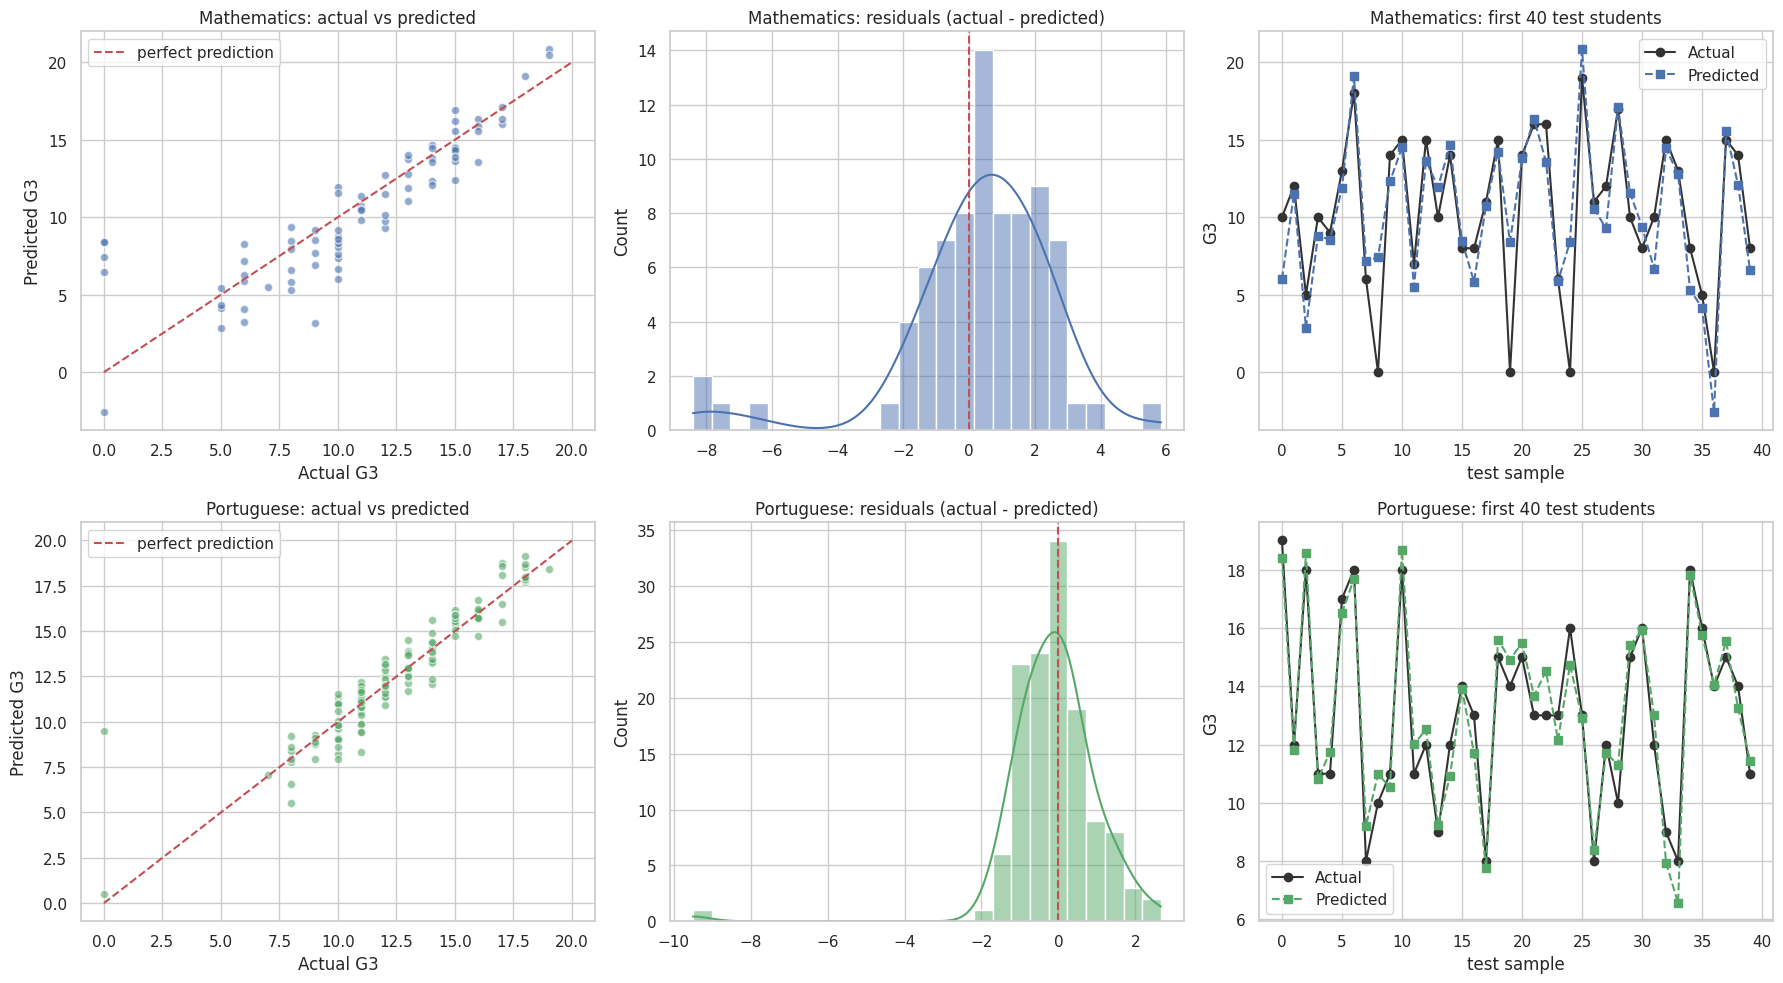

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, (name, yt, yp, col) in enumerate([("Mathematics", yte_mat, pred_mat, "#4c72b0"), ("Portuguese", yte_por, pred_por, "#55a868")]):
    ax = axes[row, 0]
    ax.scatter(yt, yp, alpha=.6, color=col, edgecolor="white")
    ax.plot([0, 20], [0, 20], "r--", label="perfect prediction")
    ax.set_xlabel("Actual G3"); ax.set_ylabel("Predicted G3"); ax.set_title(f"{name}: actual vs predicted"); ax.legend()
    res = np.asarray(yt) - yp
    sns.histplot(res, bins=25, kde=True, color=col, ax=axes[row, 1])
    axes[row, 1].axvline(0, color="r", ls="--"); axes[row, 1].set_title(f"{name}: residuals (actual - predicted)")
    n = 40
    axes[row, 2].plot(np.asarray(yt)[:n], "o-", label="Actual", color="#333")
    axes[row, 2].plot(yp[:n], "s--", label="Predicted", color=col)
    axes[row, 2].set_title(f"{name}: first {n} test students"); axes[row, 2].set_xlabel("test sample"); axes[row, 2].set_ylabel("G3"); axes[row, 2].legend()
plt.tight_layout(); plt.show()

### 5.2 / 5.4 Going further (CO5): how does the scenario and the model choice change the result?
To interpret the results and examine limitations we also run:  
**(i)** Scenario B – *without* G1 and G2 (early prediction), **(ii)** 5-fold cross-validation of Linear Regression to check that the result is not an accident of one split, and **(iii)** two alternative regressors (Ridge, Random Forest).

In [36]:
def run_scenario(df, drop_cols=()):
    X = df.drop(columns=["G3", *drop_cols]); y = df["G3"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)   # same split rows as before
    nums, cats = column_types(X)
    out = {}
    models = {"Linear Regression": LinearRegression(), "Ridge (alpha=10)": Ridge(alpha=10),
              "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)}
    for mname, m in models.items():
        pipe = Pipeline([("prep", build_preprocessor(nums, cats)), ("model", m)]).fit(Xtr, ytr)
        p = pipe.predict(Xte)
        out[mname] = {"MAE": mean_absolute_error(yte, p), "RMSE": np.sqrt(mean_squared_error(yte, p)), "R²": r2_score(yte, p)}
    lr_pipe = Pipeline([("prep", build_preprocessor(nums, cats)), ("model", LinearRegression())])
    cv = cross_val_score(lr_pipe, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2")
    return pd.DataFrame(out).T, cv

rows = []
for dname, d in [("Mathematics", df_mat), ("Portuguese", df_por)]:
    for scen, drop in [("A: with G1+G2", ()), ("B: without G1, G2", ("G1", "G2"))]:
        tbl, cv = run_scenario(d, drop)
        tbl.insert(0, "Scenario", scen); tbl.insert(0, "Dataset", dname)
        tbl["5-fold CV R² (LinReg)"] = np.where(tbl.index == "Linear Regression", f"{cv.mean():.3f} ± {cv.std():.3f}", "")
        rows.append(tbl)
comparison = pd.concat(rows)
comparison.index.name = "Model"
display(comparison.reset_index().set_index(["Dataset", "Scenario", "Model"]).round(3))

MAE   RMSE     R²  \
Dataset     Scenario          Model                                    
Mathematics A: with G1+G2     Linear Regression  1.647  2.378  0.724   
                              Ridge (alpha=10)   1.569  2.310  0.740   
                              Random Forest      1.183  1.982  0.808   
            B: without G1, G2 Linear Regression  3.395  4.196  0.141   
                              Ridge (alpha=10)   3.359  4.164  0.154   
                              Random Forest      3.077  3.861  0.273   
Portuguese  A: with G1+G2     Linear Regression  0.765  1.215  0.849   
                              Ridge (alpha=10)   0.759  1.210  0.850   
                              Random Forest      0.753  1.249  0.840   
            B: without G1, G2 Linear Regression  2.156  2.862  0.160   
                              Ridge (alpha=10)   2.101  2.815  0.188   
                              Random Forest      2.059  2.823  0.183   

                                                5-fold CV R² (LinReg)  
Dataset     Scenario          Model                                    
Mathematics A: with G1+G2     Linear Regression         0.792 ± 0.042  
                              Ridge (alpha=10)                         
                              Random Forest                            
            B: without G1, G2 Linear Regression         0.026 ± 0.151  
                              Ridge (alpha=10)                         
                              Random Forest                            
Portuguese  A: with G1+G2     Linear Regression         0.836 ± 0.034  
                              Ridge (alpha=10)                         
                              Random Forest                            
            B: without G1, G2 Linear Regression         0.246 ± 0.086  
                              Ridge (alpha=10)                         
                              Random Forest

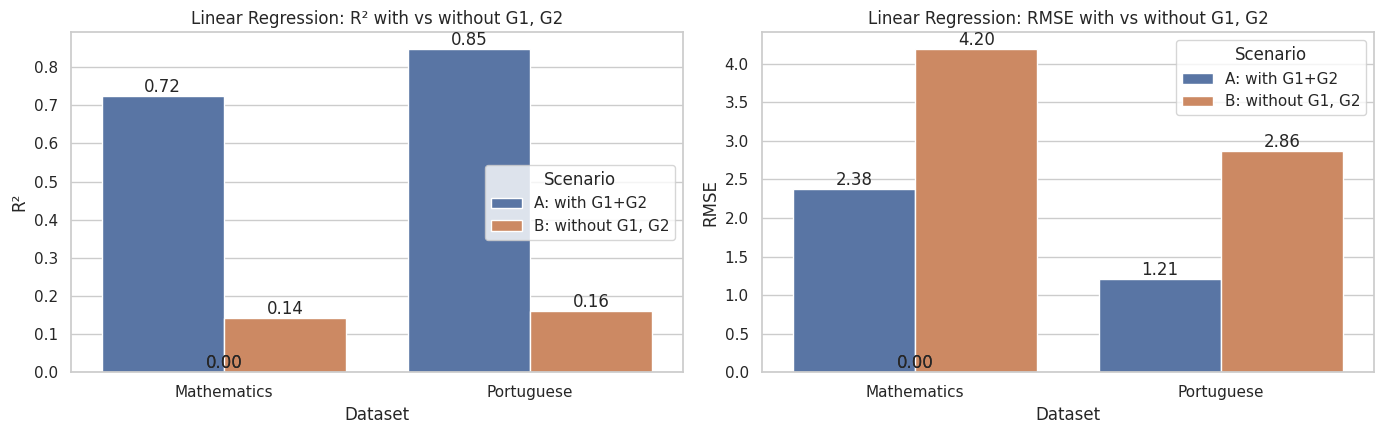

In [37]:
sc = comparison.reset_index()
lin = sc[sc["Model"] == "Linear Regression"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for a, metric in zip(axes, ["R²", "RMSE"]):
    sns.barplot(data=lin, x="Dataset", y=metric, hue="Scenario", ax=a, palette=["#4c72b0", "#dd8452"])
    a.set_title(f"Linear Regression: {metric} with vs without G1, G2")
    for p in a.patches:
        a.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()


### Interpretation of the results (Task 5)
| Dataset | MAE | RMSE | R² (test) |
|---|---|---|---|
| Mathematics | 1.65 | 2.38 | 0.72 |
| Portuguese | 0.77 | 1.21 | 0.85 |

* **Portuguese:** R² = 0.85 means the model explains about 85 % of the variance of the final grade; the average error is under one grade point (MAE 0.77 on a 0–20 scale).
* **Mathematics:** R² = 0.72 and MAE = 1.65. The model is useful but weaker. Training R² (0.87) is clearly above test R² (0.72) – a mild sign of over-fitting on the small training set (316 rows), and the test set of only 79 students is sensitive to a few outliers. 5-fold cross-validation gives a more stable R² of **0.79 ± 0.04** for Mathematics and **0.84 ± 0.03** for Portuguese.
* **RMSE > MAE** in both cases, showing that a few large errors (the G3 = 0 students) pull the squared error up.
* **Role of G1 and G2 (Scenario B):** without them, Linear Regression falls to R² = 0.14 (Math) and 0.16 (Portuguese), with MAE rising to 3.4 and 2.2. Almost all the predictive power therefore comes from the earlier grades; background factors alone (family, habits, lifestyle) explain only a small part of the final result. Which scenario is appropriate depends on the purpose: Scenario A is accurate but only available after the second period, Scenario B can be used at the start of the year but is not reliable.
* **Improvement (CO5):** Ridge regression gives a small gain, and a Random Forest improves Mathematics notably (R² 0.81, MAE 1.18) because it can capture non-linear behaviour, but it gives no gain on Portuguese where the relationship is already almost linear.



---
# Final Conclusion
**Problem:** predict a student's final grade G3 (0–20) from personal, family, social and academic information – a supervised **regression** problem, solved separately for the Mathematics and Portuguese datasets.

**Workflow carried out:** exploration (no missing values or duplicates, left-skewed target) → separate X and y and drop G3 → train/test split (80/20) → imputation, scaling and one-hot encoding fitted on training data only (no leakage) → Linear Regression → prediction → evaluation.

**Performance (Scenario A, with G1 and G2):**
| | MAE | MSE | RMSE | R² |
|---|---|---|---|---|
| Mathematics | 1.647 | 5.657 | 2.378 | 0.724 |
| Portuguese | 0.765 | 1.476 | 1.215 | 0.849 |

**Limitations**
1. Heavy reliance on G1/G2 – without them the model explains only ~15 % of the variance.
2. Linear Regression cannot model students who suddenly get G3 = 0, and can output values outside 0–20.
3. Small datasets (esp. Mathematics, 79 test rows) make the single-split metrics noisy.
4. Many attributes are self-reported survey answers on coarse scales.

**Possible improvements:** clip predictions to [0, 20]; treat G3 = 0 (drop-out) as a separate classification problem; use cross-validation and regularisation (Ridge/Lasso); try non-linear models such as Random Forest or Gradient Boosting (Random Forest raised Mathematics R² to 0.81); engineer features (e.g. G2 − G1 trend, parental education average); and combine both subjects where students overlap.
